In [1]:
import sys
from collections import defaultdict
from pathlib import Path
import pydicom
import os 
import cv2
import matplotlib.pyplot as plt

import numpy as np
from PIL import Image
import pandas as pd

from ultralytics import RTDETR

from modules.helpers import *
from modules.inference import *

## Configuration

In [2]:
WEIGHTS  = "weights/artifact_model.pt"
SAMPLE   = ""
SPLIT    = ""
DATA_ROOT = 'sample_data'
CONFS    = [0.05, 0.10, 0.25, 0.50]

# pre-tiled images
# there are PNG and DICOM helper methods in helpers.py to tile as expected by the model
tiles_dir = "image_tiles"
images_dir = "images"
# labels are expected to be in YOLO format, see examples in the artifact_labels directory
labels_dir = "artifact_labels"
tile_labels_dir = 'tile_artifact_labels'

In [3]:
# tile the images if you have not already 
TILE_SIZE = 640

def tile_png_to_disk(filename):
    stem = filename[:-4]

    try:
        # you can optionally drop completely black tiles from your generated inference dataset 
        tiles = png_to_tiles(f"{DATA_ROOT}/{images_dir}", filename, tile_size=TILE_SIZE, 
                             drop_black_tiles=True, label_path=f"{DATA_ROOT}/{labels_dir}/{stem}.txt", 
                             labels_out_dir=f"{DATA_ROOT}/{tile_labels_dir}")
    except Exception as e:
        print(f"  WARNING: could not read {stem}: {e}", flush=True)
        return -1

    for tile_idx, (patch, _) in enumerate(tiles):
        cv2.imwrite(f"{DATA_ROOT}/{tiles_dir}/{stem}__{tile_idx:02d}.png", patch)

    return len(tiles)

num_tiles = 0 
num_errors = 0 
# use pandarallel or similar to speed this up with lots of images
for image in os.listdir(f"{DATA_ROOT}/{images_dir}"):
    temp = tile_png_to_disk(image)
    if temp > 0:
        num_tiles+=temp
    else:
        num_errors+=1


print(f"Total tiles written: {num_tiles}")
print(f"Failed:              {num_errors}")

Total tiles written: 143
Failed:              0


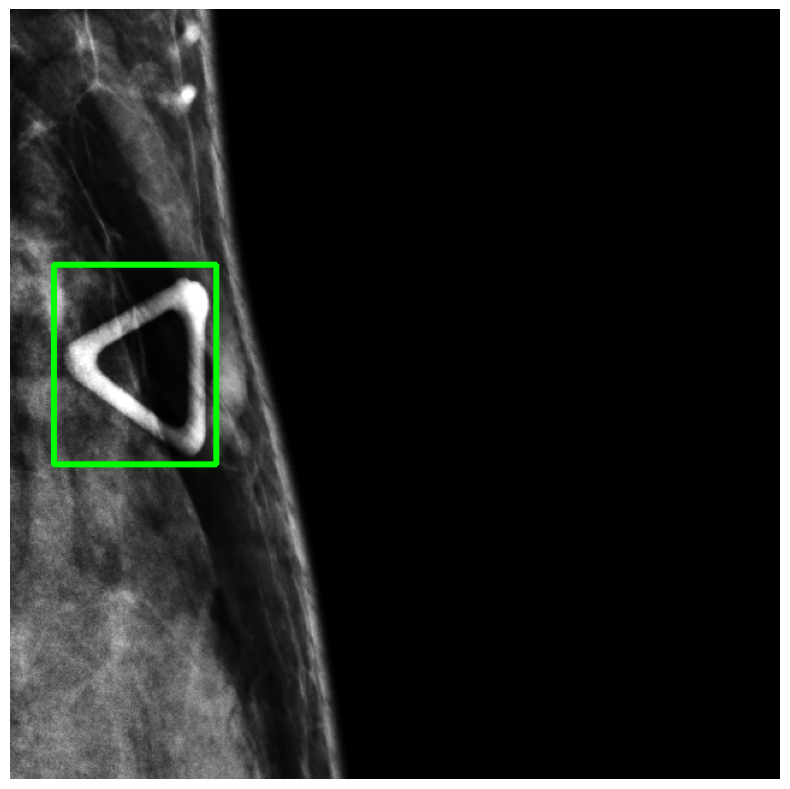

In [4]:
# check that our written tile-level labels make sense 
img_path = f"{DATA_ROOT}/{tiles_dir}/sample_9__05.png"
img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
H, W = img.shape[:2]

yolo_lbl_path = f"{DATA_ROOT}/{tile_labels_dir}/sample_9__05.txt"
colors = [(0, 255, 0), (255, 200, 0), (255, 0, 200)]

with open(yolo_lbl_path) as f:
    for line in f:
        parts = line.strip().split()
        cls = int(parts[0])
        xc, yc, w, h = [float(v) for v in parts[1:5]]
        x1 = int((xc - w/2) * W)
        y1 = int((yc - h/2) * H)
        x2 = int((xc + w/2) * W)
        y2 = int((yc + h/2) * H)
        cv2.rectangle(img_color, (x1, y1), (x2, y2), colors[cls], 4)

fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(img_color)
ax.axis("off")
plt.tight_layout()
plt.show()

In [5]:
pairs = collect_tiled_inputs(Path(f"{DATA_ROOT}/{tiles_dir}"))
gt_per_image = aggregate_gt_tiled(pairs, Path(f"{DATA_ROOT}/{tile_labels_dir}"))

n_tiles  = len(pairs)
n_images = len(gt_per_image)

print(f"Tiles:         {n_tiles}")
print(f"Source images: {n_images}")

for cls_id, name in CLASS_NAMES.items():
    n_pos = sum(1 for s in gt_per_image.values() if cls_id in s)
    print(f"  {name:5s}: {n_pos} images contain it, {n_images - n_pos} do not")

Tiles:         143
Source images: 9
  Skin : 1 images contain it, 8 do not
  Clip : 2 images contain it, 7 do not
  Wire : 0 images contain it, 9 do not


In [6]:
model = RTDETR(str(WEIGHTS))

In [7]:
preds_max_conf, all_stems = run_tiled_inference(
    model, pairs, min_thresh=min(CONFS),
    filter_cfg=None, filter_module=None, edge_pad_px=0,
)
all_stems = all_stems | set(gt_per_image.keys())
print(f"\nDone. Predictions across {len(all_stems)} source images.")

  0/143 tiles processed...
  143/143 tiles processed.

Done. Predictions across 9 source images.


## Compute metrics

In [8]:
ap_results = compute_detection_ap(
    model=model,
    pairs=pairs,
    labels_dir=Path(f"{DATA_ROOT}/{tile_labels_dir}"),
    min_conf=0.25,                         # model inference floor
    mode="tiled",
)

print_ap_table(ap_results)  # prints one block per conf threshold


  [AP] 0/143 ...
  [AP] 143/143 done.

  DETECTION AP  (box-level, COCO IoU sweep)
  Class          n_GT    AP@25    AP@50    AP@75  mAP@.5:.95
------------------------------------------------------------------------
  Skin              1    50.00%    50.00%    50.00%      35.00%
  Clip              7    71.29%    48.91%     4.95%      18.90%
  Wire              0      --        --        --          --  
  ALL (macro)       8    60.64%    49.46%    27.48%      26.95%


In [9]:
rows_per_class = defaultdict(list)
for cls_id in sorted(CLASS_NAMES.keys()):
    for thr in sorted(CONFS):
        row = compute_image_level_metrics(
            gt_per_image, preds_max_conf, all_stems, cls_id, thr,
        )
        rows_per_class[cls_id].append(row)

print_table(rows_per_class)


  SKIN (class 0)
    Images with this class:    1
    Images WITHOUT this class: 8
    Total images:              9
   conf |   TP   FN   FP   TN |   Prec    Rec   Spec     F1    Acc
---------------------------------------------------------------------------
   0.05 |    1    0    3    5 |  25.0% 100.0%  62.5%  40.0%  66.7%
   0.10 |    1    0    3    5 |  25.0% 100.0%  62.5%  40.0%  66.7%
   0.25 |    1    0    2    6 |  33.3% 100.0%  75.0%  50.0%  77.8%
   0.50 |    1    0    2    6 |  33.3% 100.0%  75.0%  50.0%  77.8%

  CLIP (class 1)
    Images with this class:    2
    Images WITHOUT this class: 7
    Total images:              9
   conf |   TP   FN   FP   TN |   Prec    Rec   Spec     F1    Acc
---------------------------------------------------------------------------
   0.05 |    2    0    2    5 |  50.0% 100.0%  71.4%  66.7%  77.8%
   0.10 |    2    0    2    5 |  50.0% 100.0%  71.4%  66.7%  77.8%
   0.25 |    2    0    0    7 | 100.0% 100.0% 100.0% 100.0% 100.0%
   0.50 |  